# QFF26 Live Lab: Build Your First Quantum Circuit
**Hands-on: build, run & measure on IBM Quantum hardware** (45 min)

| Block | Time | What you do |
|---|---|---|
| 0 | 0-5 | Setup + account check |
| 1 | 5-12 | One qubit: gates, statevector, Bloch sphere |
| 2 | 12-20 | Two qubits: build a Bell state |
| 3 | 20-30 | Qiskit Patterns: Map, Optimize, Execute, Post-process |
| 4 | 30-40 | Run on **real IBM hardware** and compare with the ideal result |
| 5 | 40-45 | Challenge: 3-qubit GHZ + wrap-up |

> **No account yet?** Leave `USE_REAL_HARDWARE = False` in Block 0. The notebook then uses a
> *noisy simulator* that copies a real IBM chip's noise, so every cell still runs.

## Block 0: Setup

In [1]:
# Run once. (Qiskit 2.x)
%pip install -q "qiskit[visualization]" qiskit-aer qiskit-ibm-runtime matplotlib


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt

import qiskit
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit.visualization import plot_histogram, plot_bloch_multivector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import SamplerV2 as Sampler, EstimatorV2 as Estimator
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime.fake_provider import FakeTorino

print("Qiskit version:", qiskit.__version__)

Qiskit version: 2.6.1


### Choose where to run
* `False` (default): local noisy simulator (no account, no queue, instant).
* `True`: real IBM Quantum QPU. Needs a saved account (cell below).

In [3]:
USE_REAL_HARDWARE = False   # <-- flip to True once your account is saved
SHOTS = 1024

In [4]:
# Save your credentials ONCE per environment, then comment this cell out.
# Get an API key + instance CRN at https://quantum.cloud.ibm.com/
#
# QiskitRuntimeService.save_account(
#     token="<YOUR_API_KEY>",
#     instance="<YOUR_INSTANCE_CRN>",   # optional if you have only one
#     overwrite=True,
#     set_as_default=True,
# )

if USE_REAL_HARDWARE:
    service = QiskitRuntimeService()
    backend = service.least_busy(operational=True, simulator=False)
    print("Hardware backend:", backend.name, f"({backend.num_qubits} qubits)")
else:
    backend = AerSimulator.from_backend(FakeTorino())   # noisy copy of a 133-qubit Heron chip
    print("Noisy simulator backend:", backend.name)

Noisy simulator backend: aer_simulator_from(fake_torino)


## Block 1: One qubit

A qubit starts in $|0\rangle$. Gates rotate its state on the **Bloch sphere**.

| Gate | Effect |
|---|---|
| `X` | flip $|0\rangle \leftrightarrow |1\rangle$ (quantum NOT) |
| `H` | $|0\rangle \to (|0\rangle+|1\rangle)/\sqrt2$ **superposition** |
| `Z` | flip the sign (phase) of $|1\rangle$ |

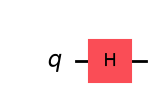

<IPython.core.display.Latex object>

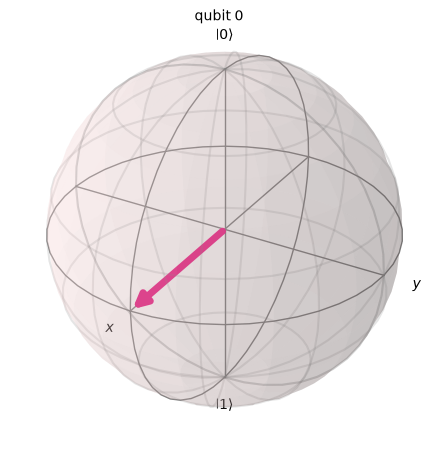

In [5]:
qc1 = QuantumCircuit(1)
qc1.h(0)
display(qc1.draw("mpl"))

sv = Statevector(qc1)               # exact math, no hardware needed
display(sv.draw("latex"))
display(plot_bloch_multivector(sv))

**Predict first:** If we measure this qubit 1000 times, what do we expect?  
Probability = (amplitude)$^2$ = $(1/\sqrt2)^2$ = 0.5 for each outcome.

### Exercise 1 (2 min)
Make the state $|1\rangle$ and then the state $(|0\rangle - |1\rangle)/\sqrt2$ (this is called $|-\rangle$).  
*Hint: `x` then `h`.* Check the Bloch sphere: where does the arrow point?

<IPython.core.display.Latex object>

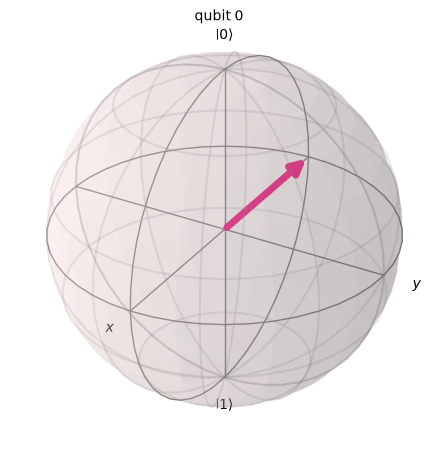

In [6]:
ex1 = QuantumCircuit(1)
# TODO: add gates so the statevector is (|0> - |1>)/sqrt(2)
ex1.x(0)
ex1.h(0)

display(Statevector(ex1).draw("latex"))
display(plot_bloch_multivector(Statevector(ex1)))

## Block 2: Two qubits and entanglement

`CX(control, target)` flips the target **only if** the control is $|1\rangle$.  
Put the control in superposition first and you get a **Bell state**:

$$|\Phi^+\rangle=\frac{|00\rangle+|11\rangle}{\sqrt2}$$

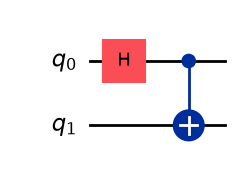

<IPython.core.display.Latex object>

In [7]:
bell = QuantumCircuit(2)
bell.h(0)          # superposition on qubit 0
bell.cx(0, 1)      # entangle qubit 1 with qubit 0
display(bell.draw("mpl"))
display(Statevector(bell).draw("latex"))

Notice: only `|00>` and `|11>` have amplitude. `|01>` and `|10>` are **impossible**.  
Each qubit alone looks random, yet the pair always agrees.

### Exercise 2 (3 min)
Build $|\Psi^+\rangle=(|01\rangle+|10\rangle)/\sqrt2$. *Hint: one extra `x`.*

In [8]:
ex2 = QuantumCircuit(2)
ex2.h(0)
ex2.cx(0, 1)
ex2.x(1)           # flips |00>,|11> into |01>,|10>
display(Statevector(ex2).draw("latex"))

<IPython.core.display.Latex object>

## Block 3: The Qiskit Pattern (Map, Optimize, Execute, Post-process)

| Step | Meaning | Qiskit tool |
|---|---|---|
| 1. **Map** | Express the problem as a circuit (+ observable) | `QuantumCircuit` |
| 2. **Optimize** | Rewrite for the target chip's gates & qubit connectivity | `generate_preset_pass_manager` |
| 3. **Execute** | Run with a *primitive* | `SamplerV2` / `EstimatorV2` |
| 4. **Post-process** | Plots, statistics | `plot_histogram` |

### Step 1: Map. Add measurements
`Sampler` returns **bitstrings**, so the circuit must measure.

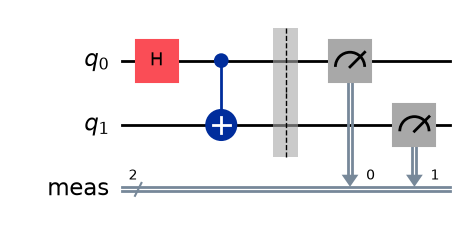

In [9]:
bell_m = bell.copy()
bell_m.measure_all()          # creates a classical register named "meas"
display(bell_m.draw("mpl"))

### Step 2: Optimize (transpile)
Real chips only understand a **native gate set** (Heron: `rz, sx, x, cz`) and only some qubit pairs are wired together.  
The transpiler converts your circuit into an **ISA circuit** (Instruction Set Architecture) the backend accepts.

Before: {'measure': 2, 'h': 1, 'cx': 1, 'barrier': 1} | depth 3
After : {'rz': 6, 'sx': 3, 'measure': 2, 'cz': 1, 'barrier': 1} | depth 8


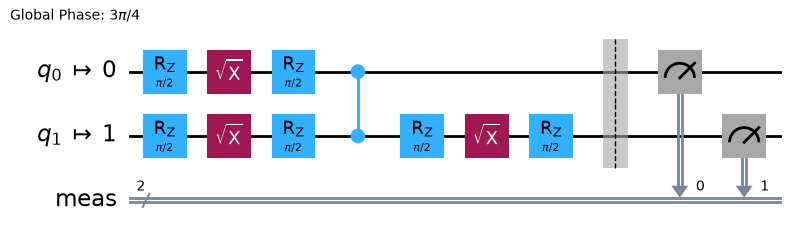

In [10]:
pm = generate_preset_pass_manager(optimization_level=1, backend=backend)
isa_bell = pm.run(bell_m)

print("Before:", dict(bell_m.count_ops()), "| depth", bell_m.depth())
print("After :", dict(isa_bell.count_ops()), "| depth", isa_bell.depth())
display(isa_bell.draw("mpl", idle_wires=False))

**Talking point:** `h` and `cx` vanished. They became `rz`, `sx` and `cz` on specific physical qubits.

### Step 3 & 4: Execute on the *ideal* simulator first (our reference)

Ideal counts: {'00': 533, '11': 491}


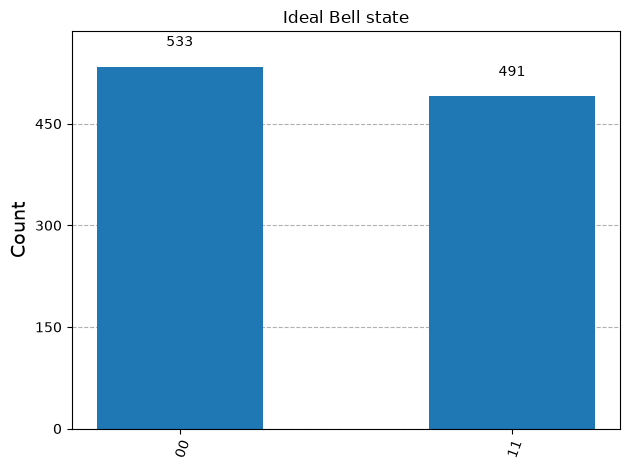

In [11]:
from qiskit.primitives import StatevectorSampler      # perfect, noise-free

ideal = StatevectorSampler().run([bell_m], shots=SHOTS).result()
ideal_counts = ideal[0].data.meas.get_counts()
print("Ideal counts:", ideal_counts)
display(plot_histogram(ideal_counts, title="Ideal Bell state"))

## Block 4: Run on the chosen backend

If `USE_REAL_HARDWARE=True` this job goes to a **real superconducting QPU** (you will wait in the queue, usually seconds to minutes).  
Otherwise it runs on the noisy simulator.

In [12]:
sampler = Sampler(mode=backend)
job = sampler.run([isa_bell], shots=SHOTS)
print("Job id:", job.job_id())
result = job.result()
hw_counts = result[0].data.meas.get_counts()
print("Backend counts:", hw_counts)

Job id: 05e644c2-6f53-411d-a050-bf8d02e7afc8
Backend counts: {'11': 405, '00': 419, '01': 103, '10': 97}


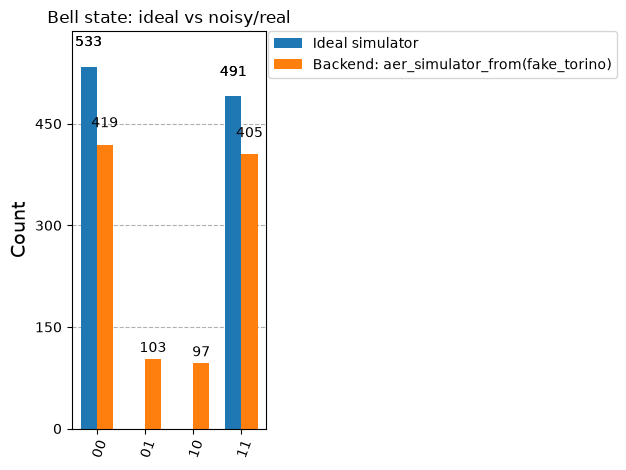

In [13]:
display(plot_histogram(
    [ideal_counts, hw_counts],
    legend=["Ideal simulator", f"Backend: {backend.name}"],
    title="Bell state: ideal vs noisy/real",
))

### Read the result
* Mostly `00` and `11`, about 50/50: **entanglement works**.
* A few `01` / `10` counts: **noise** (gate error, readout error, decoherence). They cannot happen in theory.
* This gap is why error suppression, mitigation and (later) error correction matter.

In [14]:
total = sum(hw_counts.values())
good = hw_counts.get("00", 0) + hw_counts.get("11", 0)
print(f"Bell-state fidelity proxy: {good/total:.3f}   (ideal = 1.000)")
print(f"Error counts (01 + 10)  : {total-good} of {total}")

Bell-state fidelity proxy: 0.805   (ideal = 1.000)
Error counts (01 + 10)  : 200 of 1024


### Bonus: Estimator, the other primitive
`Sampler` answers *"which bitstrings?"*. `Estimator` answers *"what is the average value of an observable?"*  
For a Bell state: $\langle ZZ\rangle = +1$ (qubits agree), $\langle XX\rangle = +1$, $\langle ZI\rangle = 0$ (each alone is random).

In [15]:
isa_bell_nomeas = pm.run(bell)                       # NO measurements for Estimator
observables = [SparsePauliOp(p) for p in ("ZZ", "XX", "ZI")]
isa_obs = [o.apply_layout(isa_bell_nomeas.layout) for o in observables]   # match the physical layout

est = Estimator(mode=backend)
est_res = est.run([(isa_bell_nomeas, isa_obs)]).result()
for name, ev in zip(("ZZ", "XX", "ZI"), est_res[0].data.evs):
    print(f"<{name}> = {ev:+.3f}")

Simulation failed and returned the following error message:
ERROR:  [Experiment 0] a circuit requires more memory than max_memory_mb. [Experiment 1] a circuit requires more memory than max_memory_mb. [Experiment 2] a circuit requires more memory than max_memory_mb. [Experiment 3] a circuit requires more memory than max_memory_mb. [Experiment 4] a circuit requires more memory than max_memory_mb. [Experiment 5] a circuit requires more memory than max_memory_mb. [Experiment 6] a circuit requires more memory than max_memory_mb. [Experiment 7] a circuit requires more memory than max_memory_mb. [Experiment 8] a circuit requires more memory than max_memory_mb. [Experiment 9] a circuit requires more memory than max_memory_mb. [Experiment 10] a circuit requires more memory than max_memory_mb. [Experiment 11] a circuit requires more memory than max_memory_mb. [Experiment 12] a circuit requires more memory than max_memory_mb. [Experiment 13] a circuit requires more memory than max_memory_mb. [Exp

ValueError: could not broadcast input array from shape (0,17) into shape (128,17)

## Block 5: Challenge, a 3-qubit GHZ state

$$|GHZ\rangle=\frac{|000\rangle+|111\rangle}{\sqrt2}$$

1. Build it (`h` + two `cx`).
2. Measure, transpile and run it on your backend.
3. What fraction of shots are *not* `000` or `111`? Is it larger than for the Bell state? Why?

GHZ counts: {'000': 373, '111': 404, '101': 16, '110': 85, '001': 86, '011': 24, '100': 25, '010': 11}
GHZ fidelity proxy: 0.759


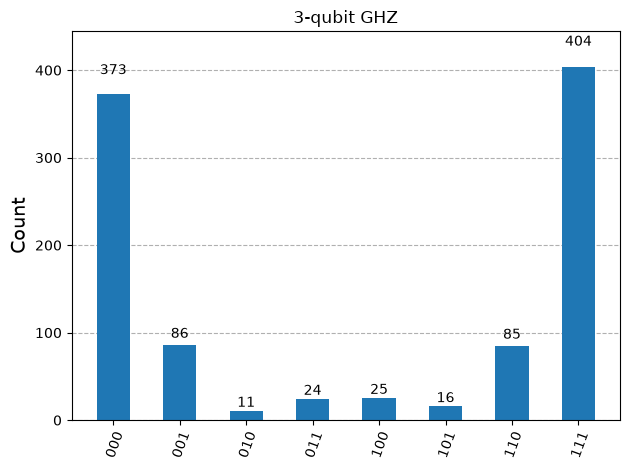

In [16]:
ghz = QuantumCircuit(3)
ghz.h(0)
ghz.cx(0, 1)
ghz.cx(1, 2)
ghz.measure_all()

isa_ghz = pm.run(ghz)
ghz_counts = Sampler(mode=backend).run([isa_ghz], shots=SHOTS).result()[0].data.meas.get_counts()

good = ghz_counts.get("000", 0) + ghz_counts.get("111", 0)
print("GHZ counts:", ghz_counts)
print(f"GHZ fidelity proxy: {good/sum(ghz_counts.values()):.3f}")
display(plot_histogram(ghz_counts, title="3-qubit GHZ"))

**Answer:** more two-qubit gates means more error. Each `cz` is the noisiest operation on the chip.

---
## Wrap-up
* You built **superposition** (`H`) and **entanglement** (`H + CX`).
* You ran the 4-step **Qiskit Pattern**.
* You saw the difference between **ideal** and **real/noisy** results.

**Next steps:** [IBM Quantum Learning](https://quantum.cloud.ibm.com/learning) · [Qiskit docs](https://quantum.cloud.ibm.com/docs) · Qiskit Global Summer School labs.